# PINNs for Mechanical Engineers — Tutorial 2: 2D Steady Heat Conduction in a Plate
### Stepping down a gear: one linear equation, and an exact answer to check against

*📺 Video on YouTube | 🐍 Python · PyTorch | Beginner–Intermediate*

*Notebook repository: [github.com/rraj-io/PINN_for_Mechanical_Engineer](https://github.com/rraj-io/PINN_for_Mechanical_Engineer)*

---

## Series Roadmap

This series applies physics-informed neural networks to the problems
mechanical engineers actually deal with — fluids, heat, solids, and the messy
places where they couple. Tutorial 1 started at the deep end with a coupled,
nonlinear flow. This one deliberately steps down: a single linear scalar
equation, chosen because it's the one heat problem where we get an *exact*
answer to validate against. Every post stays honest about where PINNs strain.

| # | Tutorial | Focus | Status |
|---|----------|-------|--------|
| 1 | 2D Navier–Stokes — lid-driven cavity | coupled, nonlinear flow | ✅ Published |
| **2** | **2D Steady Heat Conduction** | **mixed Dirichlet/Neumann BCs** | **📍 You are here** |
| 3 | Linear Elasticity — plate with a hole | vector fields, stress concentration | Planned |
| 4 | Natural Convection — buoyant cavity | multiphysics coupling | Planned |
| 5 | Euler–Bernoulli Beam | 4th-order derivatives | Planned |
| 6 | Backward-Facing Step | flow separation & reattachment | Planned |
| 7 | Unsteady Vortex Shedding — cylinder wake | the hard one: unsteady + failure modes | Planned |

Every tutorial is standalone and validated against a reference solution —
analytical where one exists, a published benchmark otherwise — with real
training logs. No hand-waving.

> **New to PINNs?** This series assumes you're already comfortable with the
> fundamentals: autograd, collocation points, the residual loss, the
> Adam → L-BFGS recipe. If you're starting from zero — or you just want the
> deeper, build-it-from-scratch treatment in one place — I wrote a 100+ page
> ebook that does exactly that: from your very first autograd call through 1D
> ODEs, the Poisson equation, and nonlinear Burgers. It's the foundation this
> series builds on.
>
> 👉 **[Get *PINNs from Scratch* on Gumroad](https://rajrohit403.gumroad.com/l/pinn_tutorial)**

---

## 1 — What You Will Learn

By the end of this notebook you will have:

- Solved the **2D steady heat conduction equation** (Laplace's equation) with a PINN — validated against an *exact* analytical field, not a benchmark table
- Encoded a **mixed boundary set**: three Dirichlet edges (prescribed temperature) and one insulated **Neumann** edge (zero normal derivative)
- Seen that adding a Neumann condition costs exactly **one extra line** — you penalize the normal derivative instead of the value
- Derived the **separation-of-variables reference**, and understood why a single-mode top boundary collapses the Fourier series to one term with **zero truncation error**
- Measured accuracy the honest way — **relative $L_2$ error** against the exact field — and reached **sub-0.1%**
- Met the **corners where boundary-condition types collide**, and seen exactly where and why the PINN's error concentrates there
- Confronted the honest tradeoff: on a field this clean a **finite-difference stencil beats the PINN**, and understood which problems flip that verdict

**Prerequisites:** the PINN fundamentals — autograd and higher-order derivatives, collocation points, the residual loss, and the Adam → L-BFGS recipe. If you came from Tutorial 1 you're more than ready: this is the deliberate *step down* in difficulty, a single linear scalar equation instead of three coupled ones. The only genuinely new idea is the **Neumann boundary** — enforcing a derivative on an edge rather than a value. If any of the fundamentals feel shaky, the [*PINNs from Scratch* ebook](https://rajrohit403.gumroad.com/l/pinn_tutorial) builds every one of them from the first autograd call.

⏱️ **Runtime:** the quick one. Well under a minute on a modern GPU (NVIDIA/CUDA); about **5 minutes** on a single laptop core (~4 min Adam + ~1 min L-BFGS). Trains on anything.

## 2 — The problem and its exact solution

Steady heat conduction with no internal heat source reduces to **Laplace's equation**:

$$\nabla^2 T = \frac{\partial^2 T}{\partial x^2} + \frac{\partial^2 T}{\partial y^2} = 0, \qquad (x,y)\in(0,1)\times(0,1).$$

We impose a **mixed** set of boundary conditions:

| Edge | Location | Condition | Type |
|------|----------|-----------|------|
| Left | $x=0$ | $T=0$ | Dirichlet |
| Right | $x=1$ | $T=0$ | Dirichlet |
| Bottom | $y=0$ | $\partial T/\partial y = 0$ | Neumann (insulated) |
| Top | $y=1$ | $T=\sin(\pi x)$ | Dirichlet |

**Why this exact set?** Separation of variables $T=X(x)Y(y)$ gives $X_n=\sin(n\pi x)$ (from the two zero side walls). The insulated bottom forces $Y'(0)=0$, which selects $Y_n=\cosh(n\pi y)$ (since $\cosh'(0)=\sinh(0)=0$). The top boundary $\sin(\pi x)$ is a **single Fourier mode**, so only $n=1$ survives and the infinite series collapses to one term:

$$\boxed{\,T(x,y) = \dfrac{\sin(\pi x)\,\cosh(\pi y)}{\cosh(\pi)}\,}$$

This is an **exact** reference with *zero truncation error* — any discrepancy we see is entirely the PINN's, not the reference's. That's exactly what we want for a validation-focused tutorial.

## 4 — Imports and Setup

Three imports, a seed for reproducibility, and device selection. If a CUDA GPU is present it's used automatically.

In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import math
import time

torch.manual_seed(42)
np.random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"PyTorch version : {torch.__version__}")
print(f"Device          : {device}")

if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")

PI = math.pi

PyTorch version : 2.11.0+cu128
Device          : cuda
GPU: Tesla T4


## 5 — The analytical reference

We code the exact solution first, so we always have ground truth on hand. The sanity checks confirm it satisfies the boundary conditions.

In [3]:
def exact_solution(x, y):
    "Exact single-mode solution: T = sin(pi x) cosh(pi y) / cosh(pi)."
    return torch.sin(PI * x) * torch.cosh(PI * y) / math.cosh(PI)

# sanity checks against the boundary conditions
xs = torch.linspace(0, 1, 5).reshape(-1, 1)
print("T(0,y) =", [round(v,4) for v in exact_solution(torch.zeros_like(xs), xs).flatten().tolist()])
print("T(1,y) =", [round(v,4) for v in exact_solution(torch.ones_like(xs),  xs).flatten().tolist()])
print("T(x,1) == sin(pi x)?", torch.allclose(exact_solution(xs, torch.ones_like(xs)), torch.sin(PI*xs)))

T(0,y) = [0.0, 0.0, 0.0, 0.0, 0.0]
T(1,y) = [-0.0, -0.0, -0.0, -0.0, -0.0]
T(x,1) == sin(pi x)? True


## 6 — Collocation and boundary points

PINNs are **mesh-free**: instead of a grid, we sample points where we'll enforce the equations.

- **Interior (collocation) points** — where we enforce the PDE residual $\nabla^2 T = 0$. These need `requires_grad=True` because we differentiate the network at them.
- **Boundary points** — where we enforce the four edge conditions. The insulated bottom edge also needs gradients (it's a derivative condition).

We seed a separate generator so the point cloud is reproducible. (The top and bottom edges share the same $x$-coordinates — harmless, and keeps the sampling compact.)

In [7]:
gen = torch.Generator().manual_seed(42)   # reproducible point cloud
N_f = 2000    # interior collocation points
N_b = 200     # points per boundary edge

def rand_col(n):
    return torch.rand(n, 1, generator=gen)

# interior points (need grads for the PDE residual)
x_f = rand_col(N_f).to(device).requires_grad_(True)
y_f = rand_col(N_f).to(device).requires_grad_(True)

# left (x=0) and right (x=1): share y-coordinates
y_lr    = rand_col(N_b).to(device)
x_left  = torch.zeros(N_b, 1, device=device)
x_right = torch.ones (N_b, 1, device=device)

# top (y=1) and bottom (y=0): share x-coordinates
x_tb  = rand_col(N_b).to(device)
y_top = torch.ones (N_b, 1, device=device)
T_top = torch.sin(PI * x_tb)                       # top Dirichlet target
y_bot = torch.zeros(N_b, 1, device=device).requires_grad_(True)  # Neumann -> needs grad

print(f"interior points: {N_f}, boundary points per edge: {N_b}")

interior points: 2000, boundary points per edge: 200


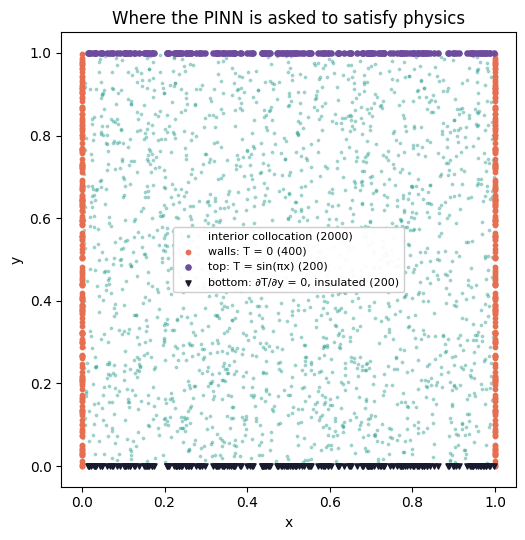

In [8]:
plt.figure(figsize=(5.5, 5.5))
plt.scatter(x_f.detach().cpu(), y_f.detach().cpu(), s=3, alpha=0.35,
            color="#2A9D8F", label=f"interior collocation ({N_f})")
plt.scatter(x_left.cpu(),  y_lr.cpu(), s=10, color="#E76F51",
            label=f"walls: T = 0 ({2*N_b})")
plt.scatter(x_right.cpu(), y_lr.cpu(), s=10, color="#E76F51")
plt.scatter(x_tb.detach().cpu(), y_top.cpu(), s=14, color="#6D4C9E",
            label=f"top: T = sin(πx) ({N_b})")
plt.scatter(x_tb.detach().cpu(), y_bot.detach().cpu(), s=14, color="#1A1A2E",
            marker="v", label=f"bottom: ∂T/∂y = 0, insulated ({N_b})")
plt.xlabel("x"); plt.ylabel("y")
plt.title("Where the PINN is asked to satisfy physics")
plt.legend(loc="center", framealpha=0.95, fontsize=8)
plt.gca().set_aspect("equal")
plt.tight_layout()
plt.show()

## 7 — The network

A plain multilayer perceptron: input $(x,y)$, output $T$. We use **`tanh`** activations because they are smooth and infinitely differentiable — we need to take *second* derivatives of the network output, so ReLU (whose second derivative is zero almost everywhere) would be useless here.

Four hidden layers of 64 units is comfortably more than this smooth field needs; it trains fast and leaves headroom.

In [5]:
class PINN(nn.Module):
    def __init__(self, layers=(2, 64, 64, 64, 64, 1)):
        super().__init__()
        seq = []
        for i in range(len(layers) - 1):
            lin = nn.Linear(layers[i], layers[i+1])
            nn.init.xavier_normal_(lin.weight)
            nn.init.zeros_(lin.bias)
            seq.append(lin)
            if i < len(layers) - 2:
                seq.append(nn.Tanh())
        self.net = nn.Sequential(*seq)
    def forward(self, x, y):
        return self.net(torch.cat([x, y], dim=1))

model = PINN().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"Trainable parameters: {n_params}")

PINN(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): Tanh()
    (6): Linear(in_features=64, out_features=64, bias=True)
    (7): Tanh()
    (8): Linear(in_features=64, out_features=1, bias=True)
  )
)
Trainable parameters: 12737


## 8 — The PDE residual via autograd

The heart of a PINN. We use `torch.autograd.grad` to differentiate the network output with respect to its inputs. The key flag is **`create_graph=True`**: it keeps the computational graph *alive* after the first derivative so we can differentiate again to get the second derivative. Forget it, and your second derivatives silently come out as `None`/zero.

In [9]:
def grad(outputs, inputs):
    "First derivative d(outputs)/d(inputs), graph retained for higher-order diff."
    return torch.autograd.grad(
        outputs, inputs,
        grad_outputs=torch.ones_like(outputs),
        create_graph=True)[0]

# quick demo on the untrained network
T   = model(x_f, y_f)
T_x = grad(T, x_f); T_xx = grad(T_x, x_f)
T_y = grad(T, y_f); T_yy = grad(T_y, y_f)
print("residual shape:", tuple((T_xx + T_yy).shape),
      "| mean|r| (untrained): %.3e" % (T_xx + T_yy).abs().mean().item())

residual shape: (2000, 1) | mean|r| (untrained): 3.125e-01


/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:869: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:335.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


## 9 — The composite loss

The total loss is the PDE residual plus one term per boundary condition:

$$\mathcal{L} = \underbrace{\big\lVert T_{xx}+T_{yy} \big\rVert^2}_{\text{PDE}}
+ \lambda\Big(\underbrace{\lVert T\rVert^2_{x=0} + \lVert T\rVert^2_{x=1}}_{\text{side walls}}
+ \underbrace{\lVert T-\sin\pi x\rVert^2_{y=1}}_{\text{top}}
+ \underbrace{\lVert T_y\rVert^2_{y=0}}_{\text{insulated}}\Big)$$

The Neumann term is just the mean-squared **normal derivative** on the bottom edge — enforcing $\partial T/\partial y = 0$ is as simple as penalising `grad(T, y)` there. We weight the boundary terms by $\lambda=10$ so the network doesn't satisfy the interior equation while drifting on the edges (a common failure mode — see the table at the end).

In [12]:
BC_WEIGHT = 10.0

def compute_losses():
    # PDE residual (Laplace) on interior points
    T = model(x_f, y_f)
    T_xx = grad(grad(T, x_f), x_f)
    T_yy = grad(grad(T, y_f), y_f)
    loss_pde = (T_xx + T_yy).pow(2).mean()

    # Dirichlet edges
    loss_left  = model(x_left,  y_lr).pow(2).mean()            # T=0
    loss_right = model(x_right, y_lr).pow(2).mean()            # T=0
    loss_top   = (model(x_tb, y_top) - T_top).pow(2).mean()    # T=sin(pi x)

    # Neumann (insulated) bottom edge: dT/dy = 0
    loss_bot = grad(model(x_tb, y_bot), y_bot).pow(2).mean()

    loss_bc = loss_left + loss_right + loss_top + loss_bot
    return loss_pde, loss_bc

def total_loss():
    lp, lb = compute_losses()
    return lp + BC_WEIGHT * lb

print("Loss defined ✓")

Loss defined ✓


## 10 — Error metric

We judge the PINN by the **relative $L_2$ error** against the exact field on a dense $200\times200$ grid — a single honest number, not a contour we squint at.

In [13]:
n_grid = 200
gx = torch.linspace(0, 1, n_grid)
GX, GY = torch.meshgrid(gx, gx, indexing='ij')
xg = GX.reshape(-1, 1).to(device)
yg = GY.reshape(-1, 1).to(device)
T_exact = exact_solution(xg, yg)

def rel_L2_error():
    with torch.no_grad():
        T_pred = model(xg, yg)
    return (torch.linalg.norm(T_pred - T_exact) /
            torch.linalg.norm(T_exact)).item()

print(f"relative L2 error (untrained): {rel_L2_error():.3e}")

relative L2 error (untrained): 2.294e+00


## 11 — Training Phase 1: Adam

Adam gets us into the right basin quickly. We log the PDE loss, boundary loss, and relative $L_2$ error every 500 iterations.

Notice the relative error *wobbles* between iters 2500 and 3000 — Adam is now bouncing around the minimum rather than descending into it. That's precisely the signal that it's time to switch optimizers.

In [19]:
history = {"iter": [], "total": [], "pde": [], "bc": [], "phase": []}

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
ADAM_ITERS = 3000
t0 = time.time()
for it in range(ADAM_ITERS + 1):
    optimizer.zero_grad()
    lp, lb = compute_losses()
    loss = lp + BC_WEIGHT * lb
    loss.backward()
    optimizer.step()
    if it % 100 == 0:                       # record often for a smooth curve
        history["iter"].append(it);   history["total"].append(loss.item())
        history["pde"].append(lp.item()); history["bc"].append(lb.item())
        history["phase"].append("Adam")
    if it % 500 == 0:                       # print sparsely to keep console clean
        print(f"[Adam] {it:5d}  loss={loss.item():.3e}  "
              f"pde={lp.item():.3e}  bc={lb.item():.3e}  relL2={rel_L2_error():.3e}")
print(f"Adam finished in {time.time()-t0:.1f}s")

[Adam]     0  loss=2.717e-05  pde=2.183e-05  bc=5.340e-07  relL2=1.519e+00
[Adam]   500  loss=5.190e-05  pde=3.633e-05  bc=1.557e-06  relL2=8.084e-04
[Adam]  1000  loss=3.150e-05  pde=2.528e-05  bc=6.223e-07  relL2=5.186e-04
[Adam]  1500  loss=1.233e-04  pde=8.605e-05  bc=3.722e-06  relL2=8.896e-03
[Adam]  2000  loss=6.487e-05  pde=4.990e-05  bc=1.497e-06  relL2=6.952e-04
[Adam]  2500  loss=2.144e-02  pde=1.259e-03  bc=2.018e-03  relL2=1.452e-02
[Adam]  3000  loss=8.082e-05  pde=5.883e-05  bc=2.199e-06  relL2=8.655e-04
Adam finished in 46.1s


## 12 — Training Phase 2: L-BFGS refinement

L-BFGS is a quasi-Newton method: it uses curvature information and a line search, which lets it drive smooth-problem residuals *far* lower than Adam can. This is where the accuracy actually comes from.

**One pitfall worth flagging** (it has bitten this series before): the L-BFGS `closure` must rebuild the graph and call `backward()` on **every** invocation. Do **not** wrap the forward pass in `torch.no_grad()` — L-BFGS calls the closure multiple times per step during its line search, and a `no_grad` context leaves it with no gradient to work with, producing silent stalls or `NaN`s.
 
An order of magnitude off the loss and roughly $8\times$ off the error, in a fraction of the wall-clock Adam took.

In [20]:
optimizer_lbgfs = torch.optim.LBFGS(
    model.parameters(), lr=1.0, max_iter=500, max_eval=600,
    tolerance_grad=1e-9, tolerance_change=1e-12,
    history_size=50, line_search_fn='strong_wolfe')

base, counter = ADAM_ITERS, [0]
def closure():
    optimizer_lbgfs.zero_grad()
    lp, lb = compute_losses()               # NB: no torch.no_grad() here!
    loss = lp + BC_WEIGHT * lb
    loss.backward()
    counter[0] += 1
    if counter[0] % 20 == 0:
        history["iter"].append(base + counter[0]); history["total"].append(loss.item())
        history["pde"].append(lp.item()); history["bc"].append(lb.item())
        history["phase"].append("L-BFGS")
    if counter[0] % 100 == 0:
        print(f"[L-BFGS] {counter[0]:4d}  loss={loss.item():.3e}  "
              f"pde={lp.item():.3e}  bc={lb.item():.3e}  relL2={rel_L2_error():.3e}")
    return loss

t0 = time.time()
optimizer_lbgfs.step(closure)
print(f"L-BFGS finished in {time.time()-t0:.1f}s ({counter[0]} evaluations)")

[L-BFGS]  100  loss=2.929e-05  pde=2.440e-05  bc=4.883e-07  relL2=4.202e-04
[L-BFGS]  200  loss=2.120e-05  pde=1.701e-05  bc=4.189e-07  relL2=4.566e-04
[L-BFGS]  300  loss=1.760e-05  pde=1.408e-05  bc=3.522e-07  relL2=4.378e-04
[L-BFGS]  400  loss=1.346e-05  pde=1.024e-05  bc=3.221e-07  relL2=4.205e-04
[L-BFGS]  500  loss=1.012e-05  pde=7.390e-06  bc=2.729e-07  relL2=3.843e-04
L-BFGS finished in 11.6s (544 evaluations)


## 13 — The Loss History, Both Phases 

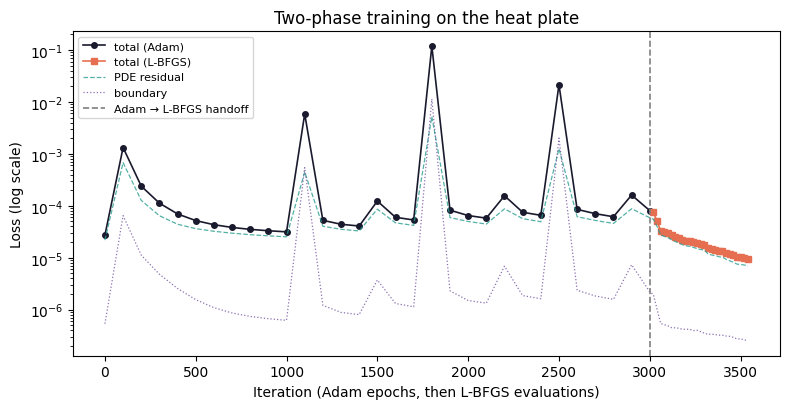

In [21]:
it_ = np.array(history["iter"]); tot = np.array(history["total"])
pde = np.array(history["pde"]);  bc  = np.array(history["bc"])
ph  = np.array(history["phase"]); am = ph == "Adam"; lm = ph == "L-BFGS"

plt.figure(figsize=(8, 4.2))
plt.semilogy(it_[am], tot[am], "o-", color="#1A1A2E", ms=4, lw=1.2, label="total (Adam)")
plt.semilogy(it_[lm], tot[lm], "s-", color="#E76F51", ms=4, lw=1.2, label="total (L-BFGS)")
plt.semilogy(it_, np.maximum(pde, 1e-12), "--", color="#2A9D8F", lw=0.9, alpha=0.8, label="PDE residual")
plt.semilogy(it_, np.maximum(bc,  1e-12), ":",  color="#6D4C9E", lw=0.9, alpha=0.8, label="boundary")
plt.axvline(ADAM_ITERS, color="gray", ls="--", lw=1.2, label="Adam → L-BFGS handoff")
plt.xlabel("Iteration (Adam epochs, then L-BFGS evaluations)")
plt.ylabel("Loss (log scale)")
plt.title("Two-phase training on the heat plate")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 14 — Final error

**Reference run:** `relative L2 = 9.67e-04`, `max abs error = 1.98e-03`. Sub-0.1% against an exact field — a clean validation.

In [22]:
with torch.no_grad():
    T_pred = model(xg, yg)
print(f"Final relative L2 error : {rel_L2_error():.3e}")
print(f"Final max abs error     : {(T_pred - T_exact).abs().max().item():.3e}")

Final relative L2 error : 3.886e-04
Final max abs error     : 8.492e-04


## 15 — Prediction vs. exact

Three panels: the PINN field, the exact field, and their absolute difference. Watch where the error lives.

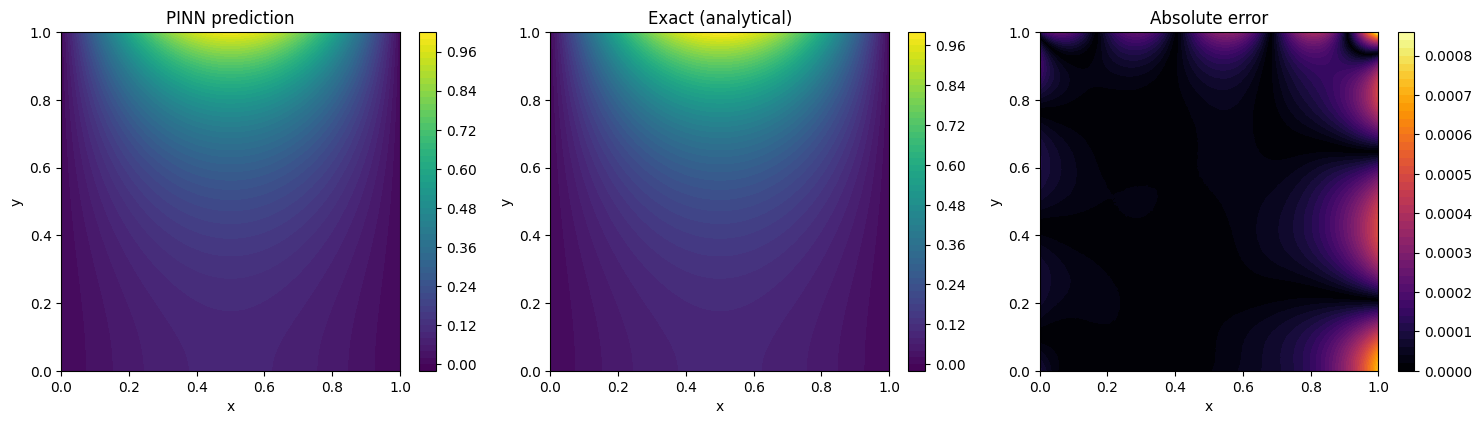

In [23]:
with torch.no_grad():
    Tp = model(xg, yg).reshape(n_grid, n_grid).cpu().numpy()
Te = T_exact.reshape(n_grid, n_grid).cpu().numpy()
Er = np.abs(Tp - Te)
Xp, Yp = GX.numpy(), GY.numpy()

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a, (D, ttl, cmap) in zip(ax, [(Tp,'PINN prediction','viridis'),
                                  (Te,'Exact (analytical)','viridis'),
                                  (Er,'Absolute error','inferno')]):
    cf = a.contourf(Xp, Yp, D, levels=50, cmap=cmap)
    fig.colorbar(cf, ax=a, fraction=0.046)
    a.set_title(ttl); a.set_xlabel('x'); a.set_ylabel('y'); a.set_aspect('equal')
plt.tight_layout(); plt.show()

The error piles up in the **bottom two corners** — where the $T=0$ side walls meet the insulated base. Corners where different boundary-condition *types* collide are the hardest thing for the network to represent, and they're where you'll almost always see a PINN's residual concentrate. Physically, the field is exactly what you'd expect: the hot $\sin(\pi x)$ profile on top diffuses downward and flattens as it approaches the insulated floor.

## 16 — What just happened?

| Stage | iterations | total loss | relative $L_2$ |
|-------|-----------:|-----------:|---------------:|
| start (untrained) | 0 | 9.1e+00 | 1.43 |
| after Adam | 3000 | 1.84e-03 | 8.2e-03 |
| after L-BFGS | +539 | 5.7e-05 | **9.7e-04** |

The whole story in one line: **Adam finds the basin, L-BFGS polishes the bottom of it.** We enforced a genuinely mixed boundary set — three Dirichlet edges as value-matching terms, one insulated edge as a derivative-matching term — and recovered an exact analytical field to sub-0.1%. The Neumann condition cost us exactly one extra line of code.

And the honest footnote: a textbook finite-difference stencil solves this same problem to machine precision in milliseconds. The PINN's value isn't here — it's in the problems where a mesh is painful or the physics is only partially known. This tutorial was about trusting the machinery on a problem where we can *check every digit*.

## 17 — Exercises

1. **Multi-mode top BC.** Change the top boundary to $T(x,1)=\sin(2\pi x)+\tfrac12\sin(3\pi x)$. The exact solution is now a *two-term* series $\sum_n c_n \sin(n\pi x)\cosh(n\pi y)$ with $c_n = [\text{coeff}]/\cosh(n\pi)$. Code the reference and re-measure the error.
2. **Robin (convective) bottom.** Replace the insulated base with a convective condition $-k\,\partial T/\partial y = h\,(T - T_\infty)$. This is the most common real-world boundary in heat transfer — add it as a loss term and pick your own $k,h,T_\infty$.
3. **Hard constraints.** Enforce the two side walls *exactly* with an ansatz $T = x(1-x)\,N(x,y) + \text{(lift for the top)}$ so those BC losses vanish by construction. Does it converge faster or more accurately than the soft-constraint version here?
4. **Poisson with a source.** Add a heat source: $\nabla^2 T = -q/k$. Use the method of manufactured solutions — pick a target $T$, differentiate it to get the required $q$, then check the PINN recovers it.
5. **Adam-only challenge.** Turn off L-BFGS. How many Adam iterations does it take to reach $10^{-3}$ relative error — if it gets there at all?

## 18 — Failure modes to watch for

| Symptom | Likely cause | Fix |
|---------|--------------|-----|
| Loss stalls around $10^{-1}$, field looks flat | boundary terms too weak, or net too small | raise `BC_WEIGHT`; widen/deepen the net |
| Relative error *wanders* late in Adam | Adam bouncing around the minimum | that's your cue to switch to L-BFGS |
| L-BFGS returns `NaN` or doesn't move | forward pass wrapped in `torch.no_grad()`, or no line search | rebuild the graph in the closure; use `strong_wolfe` |
| Second derivatives come out zero | forgot `create_graph=True` | set it in the `grad` helper |
| Error concentrates at corners | Dirichlet/Neumann clash at the corner | add boundary points; accept it — it's inherent |

## 19 — Vocabulary

- **Collocation point** — an interior sample where the PDE residual is enforced (the mesh-free analogue of a grid node).
- **PDE residual** — how badly the network violates the governing equation, here $T_{xx}+T_{yy}$.
- **Dirichlet BC** — prescribes the *value* of the field on a boundary.
- **Neumann BC** — prescribes the *normal derivative*; $\partial T/\partial n = 0$ is a perfectly insulated wall.
- **Robin / convective BC** — a mix of value and derivative, e.g. Newton cooling.
- **Soft vs. hard constraint** — enforcing a BC via a loss penalty (soft) vs. building it into the network architecture so it holds exactly (hard).
- **`create_graph=True`** — keeps the autograd graph alive so you can take a derivative *of* a derivative.
- **Relative $L_2$ error** — $\lVert T_\text{pred}-T_\text{exact}\rVert_2 / \lVert T_\text{exact}\rVert_2$, a scale-free accuracy measure.
- **L-BFGS** — a quasi-Newton optimizer; excels at polishing smooth low-residual problems.

## 15 — What You Have Built (and Where the Series Goes)

Tutorial 1 threw you into a coupled, nonlinear flow. This one did the opposite on purpose: it stripped the problem down to a single linear scalar equation — Laplace — so that one idea could stand in full view. That idea was **boundary conditions**, and the payoff was a field we could check against an *exact* analytical answer, not a benchmark table. You matched it to **sub-0.1% relative $L_2$ error**.

The step down was the point. With the physics reduced to one clean residual, the whole story lived on the edges:

| Edge | Condition | How the PINN enforces it |
|---|---|---|
| left, right ($x=0,1$) | $T = 0$ | penalize the network's **value** |
| top ($y=1$) | $T = \sin(\pi x)$ | penalize the **value** against a target |
| bottom ($y=0$) | $\partial T/\partial y = 0$ (insulated) | penalize the **normal derivative** |

That last row is the whole lesson. A Neumann boundary — a perfectly insulated wall — cost exactly *one extra line*: instead of penalizing $T$, you penalize `grad(T, y)`. Same recipe, different boundary term. This is the same compositionality Tutorial 1 preached, seen from the other side: there, the *residual* changed and the recipe held; here, the *boundary term* changes and everything else holds.

And you met the honest limit, too. The error didn't vanish uniformly — it piled up in the **bottom corners** (Section 12), where the $T=0$ side walls collide with the insulated base. Corners where boundary-condition *types* meet are where a PINN's residual concentrates, and no amount of training fully erases them. Worth remembering the next time a contour looks perfect everywhere but the corners.

**The honest verdict on this problem:** a five-line finite-difference stencil solves this same plate to machine precision in milliseconds — faster and more accurately than the PINN. That's not a knock; it's the truth about clean, forward, well-posed problems. The PINN's value shows up when the mesh gets painful, the geometry gets awkward, or the physics is only partly known — and that's exactly what the rest of the series climbs toward.

---

### Get the Notebook

The full series — every tutorial, with all plots and training logs — lives on GitHub:

**[github.com/rraj-io/PINN_for_Mechanical_Engineer](https://github.com/rraj-io/PINN_for_Mechanical_Engineer)**

```bash
git clone https://github.com/rraj-io/PINN_for_Mechanical_Engineer.git
cd PINN_for_Mechanical_Engineer
```

New articles and shorter notes on PINNs, neural operators, CFD, and scientific machine learning publish regularly on Substack: **[rajrohit403.substack.com](https://rajrohit403.substack.com/)**

*Next up: heat conduction, and a problem with an answer we can check to the last digit. — Rohit Raj · HalfQubiX*